## Advanced models

In [1]:
import joblib
from comet_ml import Experiment
import os
from util.data_aquisition import generate
from util.engineered_data_frame import engineered_data_frame

In [2]:
data = generate(seasons=[2015, 2016, 2017, 2018], play_offs=[False])

Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2015-2016
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2016-2017
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2017-2018
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2018-2019


In [3]:
df = engineered_data_frame(data)

/Users/nassimwalha/Desktop/IFT-6758/notebooks/util/util/engineered_data_frame.py:75: RuntimeWarning: invalid value encountered in double_scalars
  return 90*row['Y_Coordinate']/(np.abs(row['Y_Coordinate']))


In [4]:
df

,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,Time_Between_Events,X_Transformed,Last_X_Transformed,Distance_Last_Event,Distance_Net,Rebond,Angle,Last_Angle,Delta_Angle,Speed
0,2015020364,R,5,4,Nashville Predators,left,Arizona Coyotes,Shot,Hit,Wrist Shot,...,6,50.0,-78.0,140.527577,43.829214,False,27.149682,0.000000,27.149682,23.421263
1,2015020364,R,12,10,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Wrist Shot,...,29,77.0,69.0,29.120440,13.416408,False,26.565051,0.000000,26.565051,1.004153
2,2015020364,R,13,11,Nashville Predators,left,Arizona Coyotes,Shot,Takeaway,Wrist Shot,...,7,86.0,35.0,51.971146,12.369317,False,-75.963757,0.000000,-75.963757,7.424449
3,2015020364,R,18,17,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Backhand,...,10,82.0,69.0,19.849433,9.899495,False,45.000000,0.000000,45.000000,1.984943
4,2015020364,R,32,31,Nashville Predators,left,Arizona Coyotes,Shot,Blocked Shot,Wrist Shot,...,23,48.0,85.0,37.013511,42.201896,False,-13.706961,0.000000,-13.706961,1.609283
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021002,R,285,284,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,11,47.0,-75.0,122.690668,43.965896,True,17.198541,0.000000,17.198541,11.153697
311102,2018021002,R,286,285,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Backhand,...,8,74.0,-47.0,121.926207,15.132746,True,-7.594643,5.460213,-13.054856,15.240776
311103,2018021002,R,287,286,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,2,78.0,74.0,8.062258,12.083046,True,24.443955,-7.594643,32.038598,4.031129
311104,2018021002,R,292,291,Toronto Maple Leafs,right,Buffalo Sabres,Goal,Takeaway,Backhand,...,43,68.0,-96.0,164.027437,40.816663,False,59.036243,0.000000,59.036243,3.814592


In [5]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn import metrics
import xgboost as xgb
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from util.metrics_visualization import generate_four_curves

In [6]:
features_columns = ['Period_Time_Seconds', 'Period', 'X_Coordinate', 'Y_Coordinate', 'Distance_Net', 'Angle',
                    'Shoot_Type', 'Last_Event_Type', 'Last_Coordinate_X', 'Last_Coordinate_Y',
                    'Time_Between_Events', 'Distance_Last_Event', 'Rebond', 'Delta_Angle', 'Speed',
                    'Powerplay_Since', 'Friendly_Non_Goalies','Opponent_Non_Goalies']
df_features = df[features_columns]
df_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)
df = df_features
df.info()

/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_3849/3377483367.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_features["is_goal"]=df["Event_Type"].map(lambda x: 1 if x=="Goal" else 0)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311106 entries, 0 to 311105
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Period_Time_Seconds   311106 non-null  int64  
 1   Period                311106 non-null  int64  
 2   X_Coordinate          311088 non-null  float64
 3   Y_Coordinate          311088 non-null  float64
 4   Distance_Net          311086 non-null  float64
 5   Angle                 311085 non-null  float64
 6   Shoot_Type            311068 non-null  object 
 7   Last_Event_Type       311106 non-null  object 
 8   Last_Coordinate_X     306148 non-null  float64
 9   Last_Coordinate_Y     306149 non-null  float64
 10  Time_Between_Events   311106 non-null  int64  
 11  Distance_Last_Event   306133 non-null  float64
 12  Rebond                311106 non-null  bool   
 13  Delta_Angle           311081 non-null  float64
 14  Speed                 306112 non-null  float64
 15  

In [7]:
df = df.dropna()

In [8]:
df["Rebond"] = df["Rebond"].map(lambda x: 1 if x else 0)

/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_3849/3740469922.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Rebond"] = df["Rebond"].map(lambda x: 1 if x else 0)


In [9]:
df = df[df.Speed!=np.inf]

In [10]:
df.is_goal.value_counts()

0    273317
1     27173
Name: is_goal, dtype: int64

In [11]:
df

,Period_Time_Seconds,Period,X_Coordinate,Y_Coordinate,Distance_Net,Angle,Shoot_Type,Last_Event_Type,Last_Coordinate_X,Last_Coordinate_Y,Time_Between_Events,Distance_Last_Event,Rebond,Delta_Angle,Speed,Powerplay_Since,Friendly_Non_Goalies,Opponent_Non_Goalies,is_goal
0,36,1,50.0,20.0,43.829214,27.149682,Wrist Shot,Hit,-78.0,-38.0,6,140.527577,0,27.149682,23.421263,0,5,5,0
1,108,1,77.0,6.0,13.416408,26.565051,Wrist Shot,Faceoff,69.0,-22.0,29,29.120440,0,26.565051,1.004153,0,5,5,0
2,115,1,86.0,-12.0,12.369317,-75.963757,Wrist Shot,Takeaway,35.0,-2.0,7,51.971146,0,-75.963757,7.424449,0,5,5,0
3,193,1,82.0,7.0,9.899495,45.000000,Backhand,Faceoff,69.0,22.0,10,19.849433,0,45.000000,1.984943,0,5,5,0
4,309,1,48.0,-10.0,42.201896,-13.706961,Wrist Shot,Blocked Shot,85.0,-11.0,23,37.013511,0,-13.706961,1.609283,0,5,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,1008,3,-47.0,13.0,43.965896,17.198541,Wrist Shot,Shot,75.0,0.0,11,122.690668,1,17.198541,11.153697,0,5,5,0
311102,1016,3,74.0,-2.0,15.132746,-7.594643,Backhand,Shot,-47.0,13.0,8,121.926207,1,-13.054856,15.240776,0,5,5,0
311103,1018,3,78.0,5.0,12.083046,24.443955,Wrist Shot,Shot,74.0,-2.0,2,8.062258,1,32.038598,4.031129,0,5,5,0
311104,1083,3,-68.0,35.0,40.816663,59.036243,Backhand,Takeaway,96.0,32.0,43,164.027437,0,59.036243,3.814592,0,5,5,1


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 300490 entries, 0 to 311105
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Period_Time_Seconds   300490 non-null  int64  
 1   Period                300490 non-null  int64  
 2   X_Coordinate          300490 non-null  float64
 3   Y_Coordinate          300490 non-null  float64
 4   Distance_Net          300490 non-null  float64
 5   Angle                 300490 non-null  float64
 6   Shoot_Type            300490 non-null  object 
 7   Last_Event_Type       300490 non-null  object 
 8   Last_Coordinate_X     300490 non-null  float64
 9   Last_Coordinate_Y     300490 non-null  float64
 10  Time_Between_Events   300490 non-null  int64  
 11  Distance_Last_Event   300490 non-null  float64
 12  Rebond                300490 non-null  int64  
 13  Delta_Angle           300490 non-null  float64
 14  Speed                 300490 non-null  float64
 15  

In [13]:
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:,:-1], df.iloc[:,-1], test_size = 0.20, random_state=42)

In [15]:
features_to_standardize = ['Period_Time_Seconds',  'X_Coordinate', 'Y_Coordinate', 'Distance_Net', 'Angle',
                     'Last_Coordinate_X', 'Last_Coordinate_Y',
                    'Time_Between_Events', 'Distance_Last_Event', 'Delta_Angle', 'Speed',
                    'Powerplay_Since']
features_one_hot = ['Shoot_Type', 'Last_Event_Type']
features_to_keep = ['Period', 'Rebond', 'Friendly_Non_Goalies','Opponent_Non_Goalies']
my_transformer = ColumnTransformer([('standard', StandardScaler(), features_to_standardize),
                                    ('one-hot', OneHotEncoder(handle_unknown='ignore'), features_one_hot)],
                                   remainder='passthrough')
X_train = my_transformer.fit_transform(X_train)
X_test = my_transformer.transform(X_test)
y_test.reset_index(inplace= True, drop=True)
y_train.reset_index(inplace= True, drop=True)
transformed_features = my_transformer.get_feature_names_out()
transformed_features

array(['standard__Period_Time_Seconds', 'standard__X_Coordinate',
       'standard__Y_Coordinate', 'standard__Distance_Net',
       'standard__Angle', 'standard__Last_Coordinate_X',
       'standard__Last_Coordinate_Y', 'standard__Time_Between_Events',
       'standard__Distance_Last_Event', 'standard__Delta_Angle',
       'standard__Speed', 'standard__Powerplay_Since',
       'one-hot__Shoot_Type_Backhand', 'one-hot__Shoot_Type_Deflected',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Tip-In', 'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'one-hot__Last_Event_Type_Blocked Shot',
       'one-hot__Last_Event_Type_Faceoff',
       'one-hot__Last_Event_Type_Giveaway',
       'one-hot__Last_Event_Type_Goal', 'one-hot__Last_Event_Type_Hit',
       'one-hot__Last_Event_Type_Missed Shot',
       'one-hot__Last_Event_Type_Penalty',
       'one-hot__Last_Event_Type_Shot',
       'one-hot__Last_Event_Type

## Model on distance and angle

Dans ce notebook, quand on parle de f1 score, on va parler de macro f1, qui représente la moyenne non-pondérée des scores f1 calculées pour chacune des deux classes. En faisant ça, le non-balancement des classes n'a plus une grande influence sur la métrique.

In [15]:
#exp = Experiment(api_key=os.environ.get("COMET_API_KEY"), workspace="nassim-walha", project_name="ds-milestone2")
#exp.add_tag("XGBOOST Distance and angle")
X_train_angle_and_distance = X_train[:,3:5]
X_test_angle_and_distance = X_test[:,3:5]
# Use "gpu_hist" for training the model.
classi = xgb.XGBClassifier()#tree_method="gpu_hist")
# Fit the model using predictor X and response y.
model_xgb = classi.fit(X_train_angle_and_distance, y_train)

print('Accuracy on training data: ', round(model_xgb.score(X_train_angle_and_distance,y_train),2))
result_xgb = model_xgb.score(X_test_angle_and_distance,y_test)
print('Accuracy on testing data: ', round(result_xgb*100,2))

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nassim-walha/ds-milestone2/4b6ad0809a764af2a0bdb1d243204b96

COMET WARNING: You must install graphviz to plot tree


Accuracy on training data:  0.91
Accuracy on testing data:  90.96


f1 score: 0.4781543059339255


COMET INFO: ---------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     url                   : https://www.comet.com/nassim-walha/ds-milestone2/4b6ad0809a764af2a0bdb1d243204b96
COMET INFO:   Metrics:
COMET INFO:     accuracy : 0.9095810176711372
COMET INFO:     auc      : 0.7056157768264071
COMET INFO:     f1_score : 0.4781543059339255
COMET INFO:   Parameters:
COMET INFO:     begin_iteration : 0
COMET INFO:     end_iteration   : 99
COMET INFO:     objective       : binary:logistic
COMET INFO:     rank            : 0
COMET INFO:     world_size      : 1
COMET INFO:   Uploads:
COMET INFO:     conda-environment-definition : 1
COMET INFO:     conda-info                   : 1
COMET INFO:     conda-specification          : 1
COMET INFO:     environment details          : 1
COMET INFO:     filename                     : 1
COMET INFO:     git metadata                 :

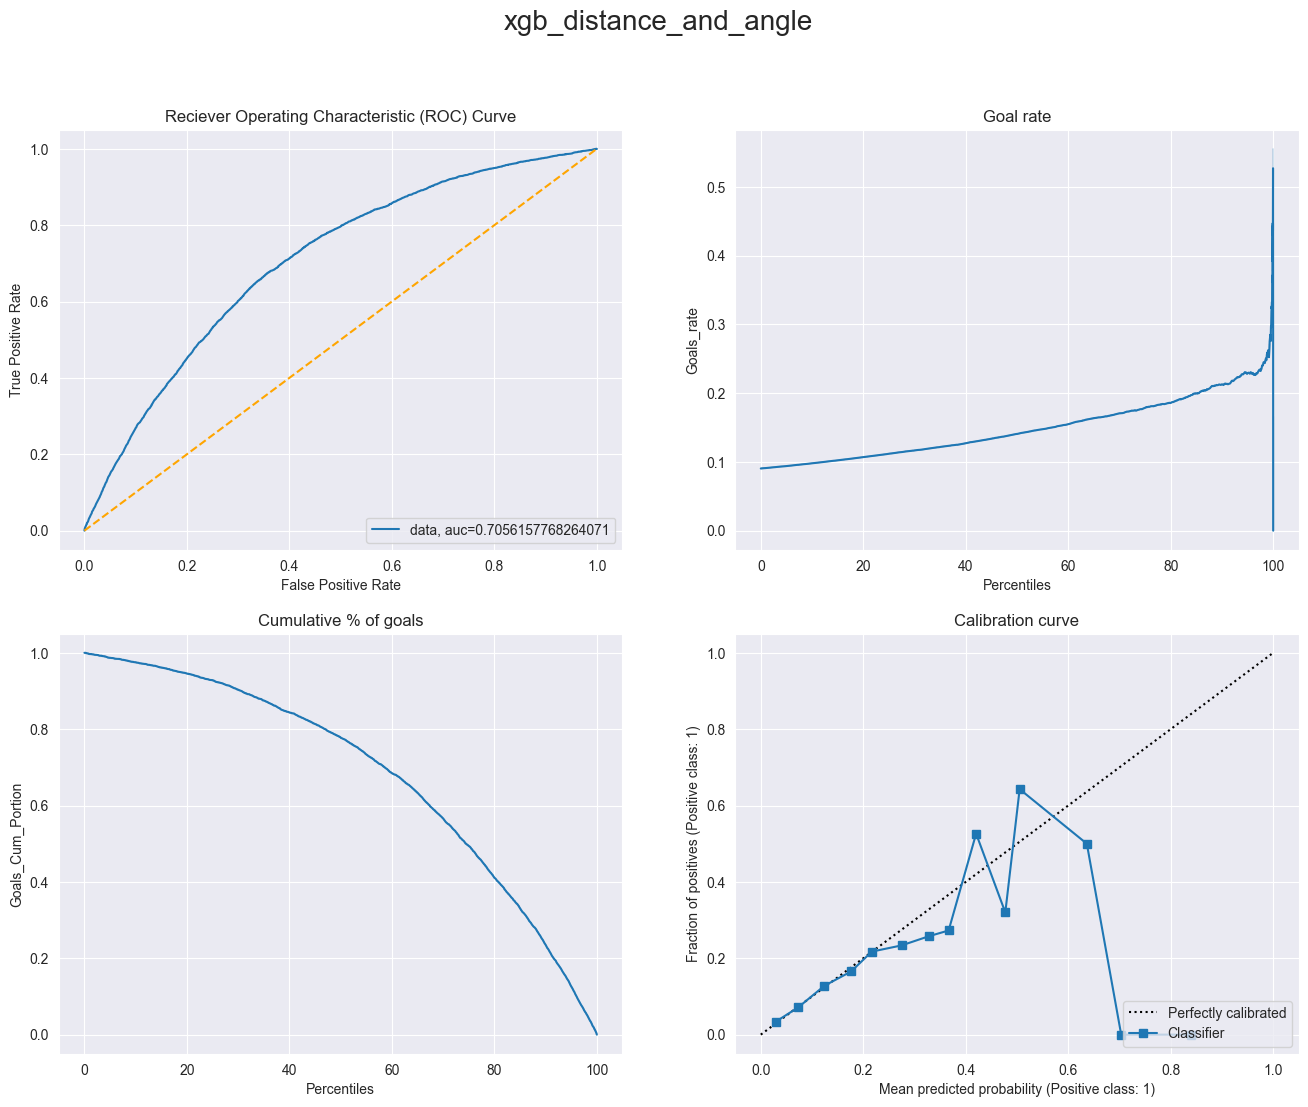

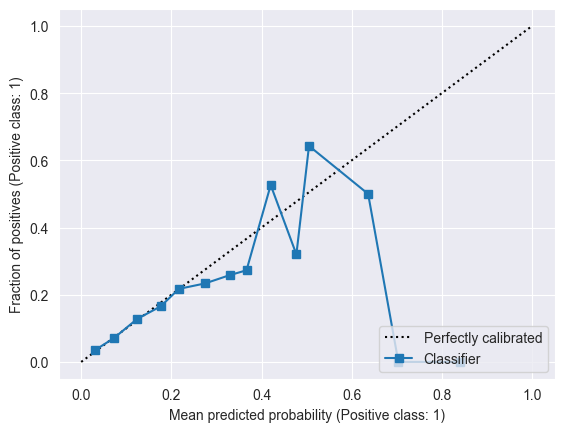

In [16]:
fig = generate_four_curves("xgb_distance_and_angle", y_test, classi.predict_proba(X_test_angle_and_distance)[:,1], 20)
f1 = metrics.f1_score(y_test, classi.predict(X_test_angle_and_distance ), average='macro')
print(f"f1 score: {f1}")
auc = metrics.roc_auc_score(y_test, classi.predict_proba(X_test_angle_and_distance)[:,1])
#exp.log_metric("accuracy", result_xgb)
#exp.log_metric("f1_score", f1)
#exp.log_metric("auc", auc)
#model_xgb.save_model("models/xgb_dist_angle.json")
#exp.log_model("XGB Dist Angle", "models/xgb_dist_angle.json")
#exp.end()

La performance est légèrement meilleure en terme de AUC par rapport à la resgression logistique (0.70 vs 0.68) et beaucoup meilleure en terme de calibration mais on ne peut pas encore dire que ce modèle est bien calibré.

In [17]:
max(classi.predict_proba(X_test_angle_and_distance)[:,1])

0.8394396

### Model on all features + Hyperparameter tuning

In [18]:
#exp = Experiment(api_key=os.environ.get("COMET_API_KEY"), workspace="nassim-walha", project_name="ds-milestone2")
#exp.add_tag("XGBOOST ALL Features")
# Use "gpu_hist" for training the model.
classi = xgb.XGBClassifier()#tree_method="gpu_hist")
# Fit the model using predictor X and response y.
model_xgb = classi.fit(X_train, y_train)

print('Accuracy on training data: ', round(model_xgb.score(X_train,y_train),2))
result_xgb = model_xgb.score(X_test,y_test)
print('Accuracy on testing data: ', round(result_xgb*100,2))

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nassim-walha/ds-milestone2/60c653f1d7d144f2a4b2b869818b98a2



Accuracy on training data:  0.91
Accuracy on testing data:  90.99


f1 score: 0.4995834225609866


COMET INFO: ---------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     url                   : https://www.comet.com/nassim-walha/ds-milestone2/60c653f1d7d144f2a4b2b869818b98a2
COMET INFO:   Metrics:
COMET INFO:     accuracy : 0.9098638889813305
COMET INFO:     auc      : 0.7487445099748395
COMET INFO:     f1_score : 0.4995834225609866
COMET INFO:   Parameters:
COMET INFO:     begin_iteration : 0
COMET INFO:     end_iteration   : 99
COMET INFO:     objective       : binary:logistic
COMET INFO:     rank            : 0
COMET INFO:     world_size      : 1
COMET INFO:   Uploads:
COMET INFO:     conda-environment-definition : 1
COMET INFO:     conda-info                   : 1
COMET INFO:     conda-specification          : 1
COMET INFO:     environment details          : 1
COMET INFO:     filename                     : 1
COMET INFO:     git metadata                 :

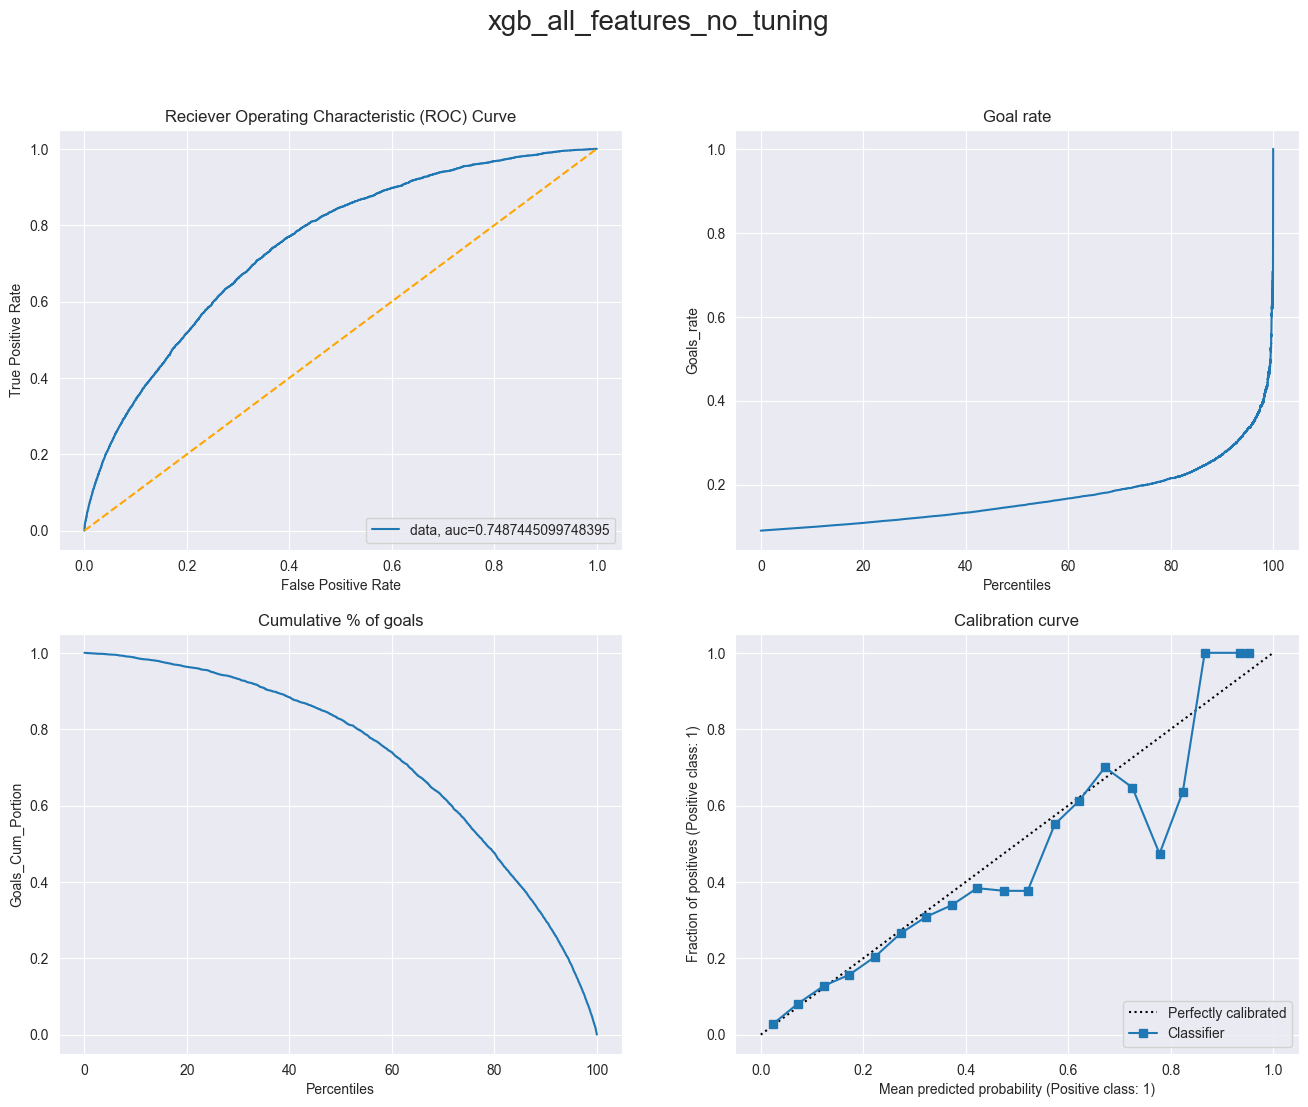

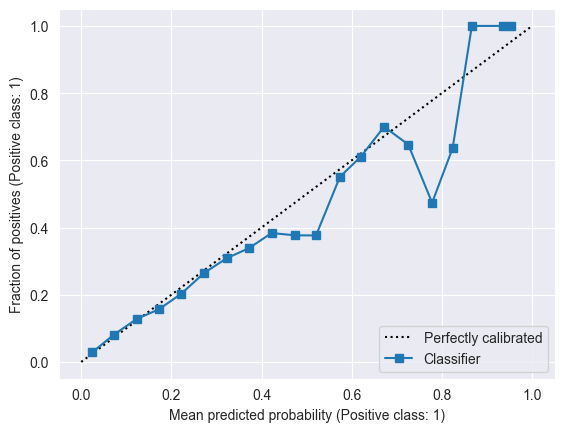

In [19]:
fig = generate_four_curves("xgb_all_features_no_tuning", y_test, classi.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, classi.predict(X_test), average='macro')
print(f"f1 score: {f1}")
auc = metrics.roc_auc_score(y_test, classi.predict_proba(X_test)[:,1])
#exp.log_metric("accuracy", result_xgb)
#exp.log_metric("f1_score", f1)
#exp.log_metric("auc", auc)
#model_xgb.save_model("models/xgb_all_features.json")
#exp.log_model("XGB ALL", "models/xgb_all_features.json")
#exp.end()

La performance est meilleure qu'avec seulement distance et angle (AUC 0.74 vs 0.70) et le modèle est mieux calibré. Aussi le f1 score est légèrement meilleur (0.499 vs 0.478) mais on peut mieux faire.

In [20]:
max(classi.predict_proba(X_test)[:,1])

0.953539

We start tuning our hyperparams. Since we are not familiar with XGBOOST, we found this page helpful for choosing our target hyperparameters to tune [XBOOST Calibration](https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html]) . Since we are not aiming to correctly classify the goals but more to have good predicted probabilities, we can't rely on metrics such as accuracy, tpr and so on.. The ideal thing would be to have a metric that represents the calibration of our model, but such a metric is not available on scikit-learn and we need to manually examine the calibration curve. So we decide for now to choose f1 score and auc as metrics, because they work well with imbalanced data

In [21]:
from sklearn.model_selection import RandomizedSearchCV

tuned_parameters = {
  'gamma': np.linspace(0, 2, num=50),
  'max_depth': np.linspace(0, 12, num=13, dtype=int),
    'max_delta_step': np.linspace(0,10, num=11),
     'scale_pos_weight': [0.1, 1.0]
  }



grid_search = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method="gpu_hist"), tuned_parameters, n_iter=150, scoring='f1_macro', cv=5,
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [22]:
print("Meilleur ensemble de paramètres trouvé")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé

{'scale_pos_weight': 1.0, 'max_depth': 0, 'max_delta_step': 10.0, 'gamma': 0.4081632653061224}
0.5184945022548388


Meilleur ensemble de paramètres trouvé:

{'scale_pos_weight': 1.0, 'max_depth': 0, 'max_delta_step': 10.0, 'gamma': 0.4081632653061224}
0.5184945022548388


In [22]:
#model = grid_search.best_estimator_
model = xgb.XGBClassifier(#tree_method= 'gpu_hist',
                          scale_pos_weight= 1.0, max_depth=50, max_delta_step = 10.0, gamma=0.4081632653061224)
model.fit(X_train, y_train)


XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, feature_types=None, gamma=0.4081632653061224,
              gpu_id=-1, grow_policy='depthwise', importance_type=None,
              interaction_constraints='', learning_rate=0.300000012,
              max_bin=256, max_cat_threshold=64, max_cat_to_onehot=4,
              max_delta_step=10.0, max_depth=50, max_leaves=0,
              min_child_weight=1, missing=nan, monotone_constraints='()',
              n_estimators=100, n_jobs=0, num_parallel_tree=1, predictor='auto',
              random_state=0, ...)

f1 score: 0.5170787000853223


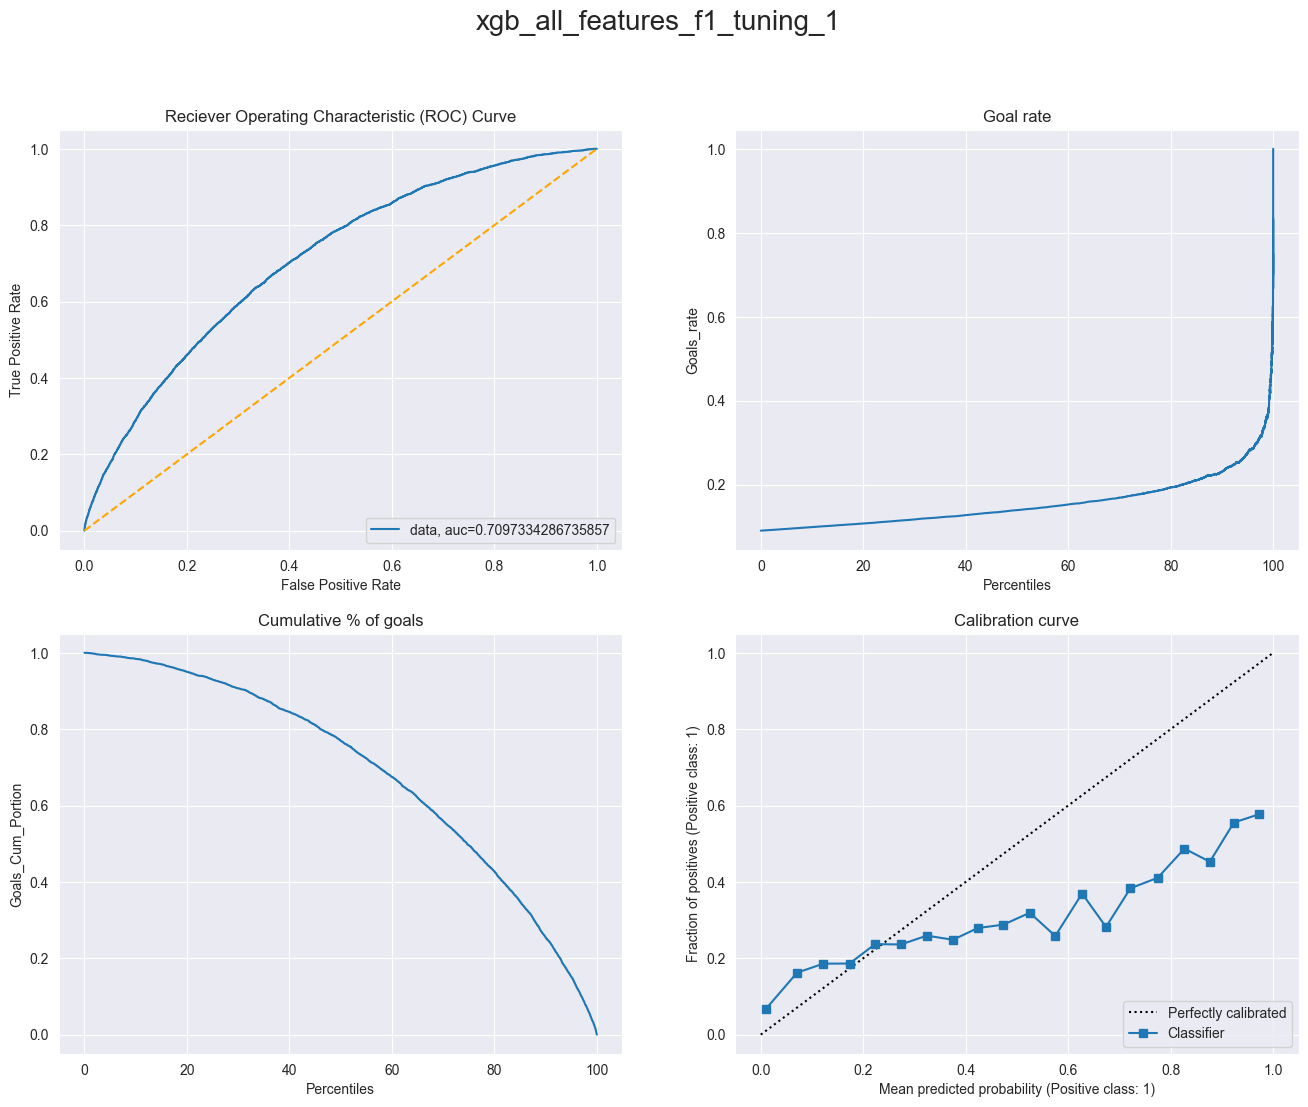

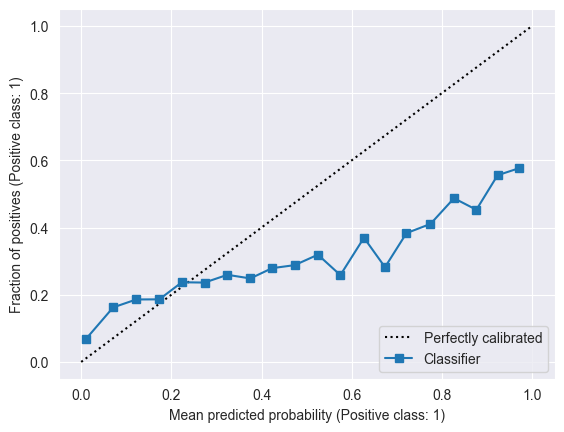

In [23]:
fig = generate_four_curves("xgb_all_features_f1_tuning_1", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
print(f"f1 score: {f1}")

C'est vrai que le score f1 est plus élevé qu'avant, mais se concentrer sur ce score comme objectif de Hyperparameter Tuning nous a coûté en terme de calibration, qui est quand même la propriété la plus importante (notion de buts éspérés). On essaye alors de faire le tuning mais avec la métrique AUC comme objectif.

In [25]:
from sklearn.model_selection import RandomizedSearchCV


tuned_parameters = {
  'gamma': np.linspace(0, 2, num=50),
  'max_depth': np.linspace(0, 12, num=13, dtype=int),
    'max_delta_step': np.linspace(0,20, num=11)
     # 'scale_pos_weight': [0.1, 1.0]
  }



grid_search = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method="gpu_hist"), tuned_parameters, n_iter=150, scoring='roc_auc', cv=5,
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [26]:
print("Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:

{'max_depth': 5, 'max_delta_step': 6.0, 'gamma': 1.7959183673469385}
0.7577426207099724


Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:

{'max_depth': 5, 'max_delta_step': 6.0, 'gamma': 1.7959183673469385}
0.7577426207099724

In [24]:
#model = grid_search.best_estimator_
model = xgb.XGBClassifier( max_depth=5, max_delta_step = 6, gamma=1.7959183673469385)#, tree_method = 'gpu_hist')
model.fit(X_train, y_train)


XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
              early_stopping_rounds=None, enable_categorical=False,
              eval_metric=None, feature_types=None, gamma=1.7959183673469385,
              gpu_id=-1, grow_policy='depthwise', importance_type=None,
              interaction_constraints='', learning_rate=0.300000012,
              max_bin=256, max_cat_threshold=64, max_cat_to_onehot=4,
              max_delta_step=6, max_depth=5, max_leaves=0, min_child_weight=1,
              missing=nan, monotone_constraints='()', n_estimators=100,
              n_jobs=0, num_parallel_tree=1, predictor='auto', random_state=0, ...)

f1 score: 0.4973061828280788


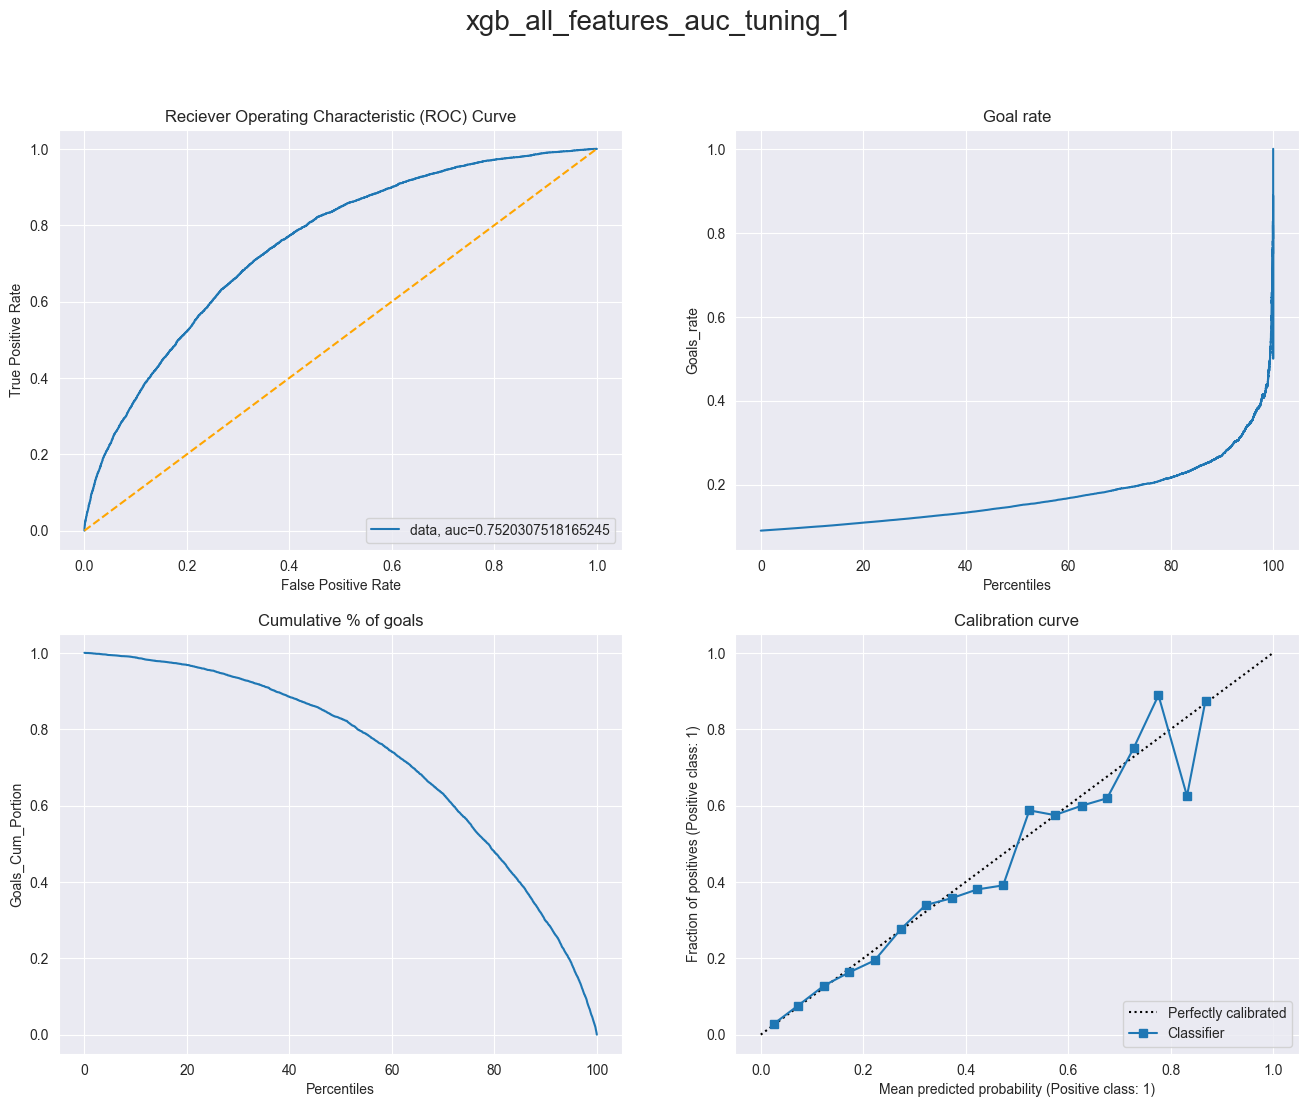

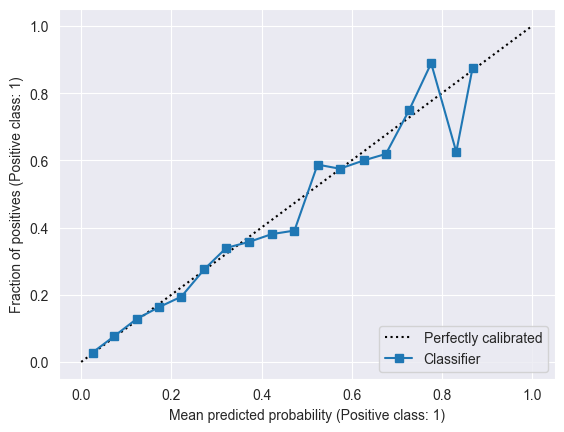

In [25]:
fig = generate_four_curves("xgb_all_features_auc_tuning_1", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test),average='macro')
print(f"f1 score: {f1}")

Ce modèle est meilleur en terme de AUC (0.75 vs 0.74) et en terme de calibration, par rapport au modèle avec toutes les caractéristiques mais sans Optimization d'Hypermaramètres. Mais l'amélioration est très légère et on peut mieux faire.

In [29]:
from sklearn.model_selection import RandomizedSearchCV


tuned_parameters = {
  'gamma': np.linspace(0, 3, num=70),
  # 'max_depth': np.linspace(0, 12, num=13, dtype=int),
    'max_delta_step': np.linspace(0,10, num=11),
     # 'scale_pos_weight': [0.1, 1.0],
    'eta': np.linspace(0,0.3, num=50)
  }



grid_search = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method="gpu_hist"), tuned_parameters, n_iter=150, scoring='roc_auc', cv=5,
)
grid_search.fit(X_train, y_train);
print('Finished!')

Finished!


In [30]:
print("Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:

{'max_delta_step': 4.0, 'gamma': 1.5652173913043477, 'eta': 0.12857142857142856}
0.7598938255727682


Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:

{'max_delta_step': 4.0, 'gamma': 1.5652173913043477, 'eta': 0.12857142857142856}
0.7598938255727682

In [26]:
#model = grid_search.best_estimator_
model = xgb.XGBClassifier(max_delta_step = 4, gamma=1.5652173913043477,
                          eta=0.12857142857142856)#, tree_method = 'gpu_hist')
model.fit(X_train, y_train)

XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
              early_stopping_rounds=None, enable_categorical=False,
              eta=0.12857142857142856, eval_metric=None, feature_types=None,
              gamma=1.5652173913043477, gpu_id=-1, grow_policy='depthwise',
              importance_type=None, interaction_constraints='',
              learning_rate=0.128571436, max_bin=256, max_cat_threshold=64,
              max_cat_to_onehot=4, max_delta_step=4, max_depth=6, max_leaves=0,
              min_child_weight=1, missing=nan, monotone_constraints='()',
              n_estimators=100, n_jobs=0, num_parallel_tree=1, predictor='auto', ...)

f1 score: 0.4927375809560121


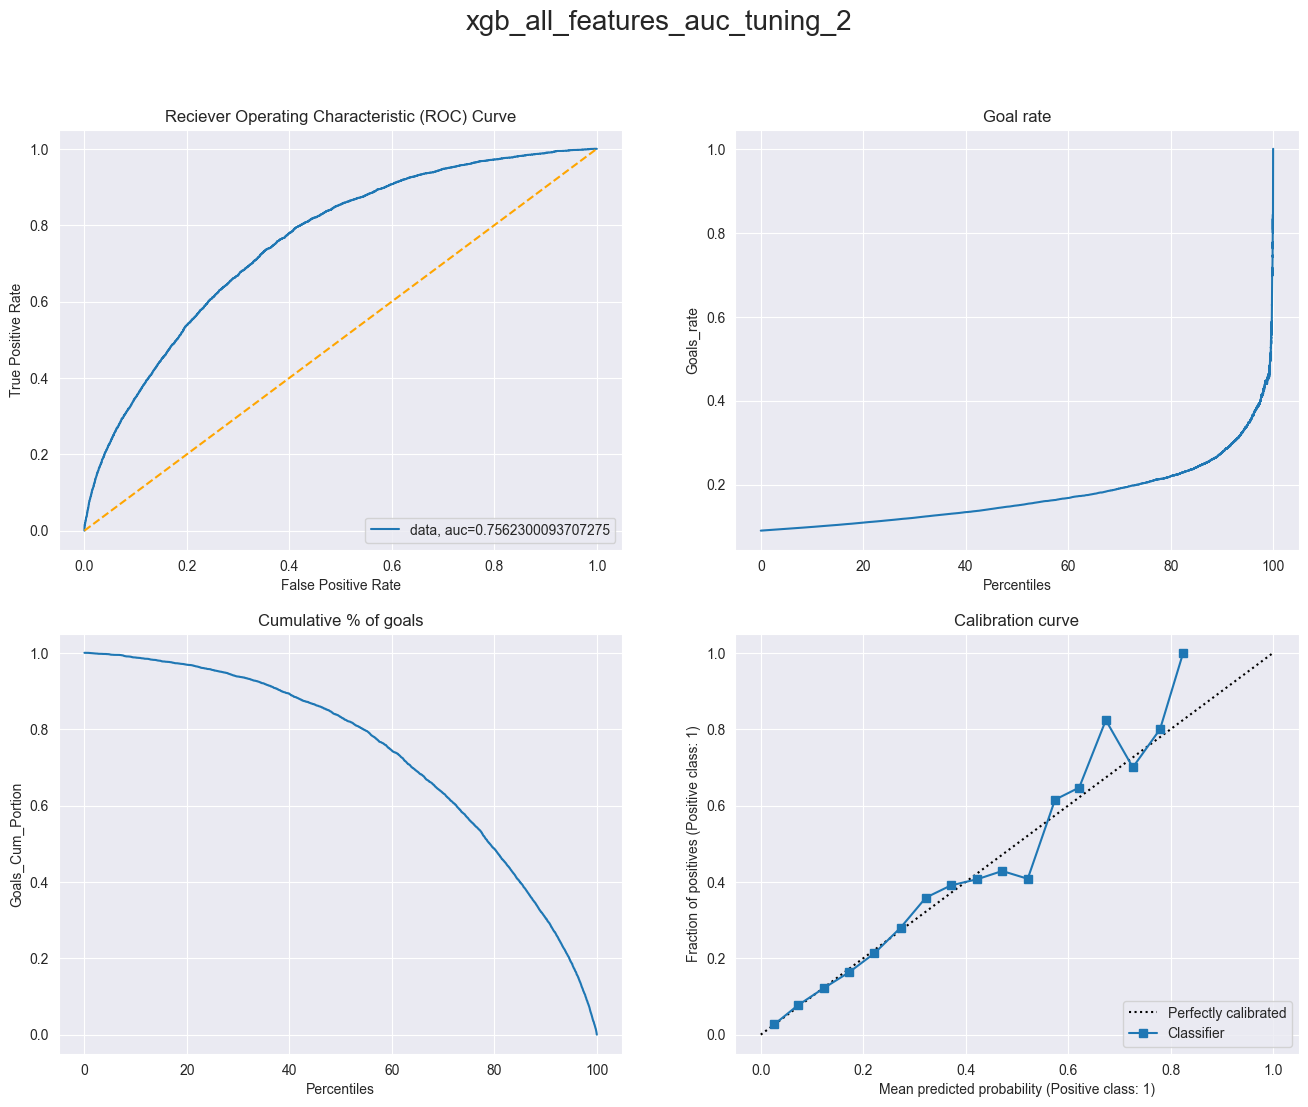

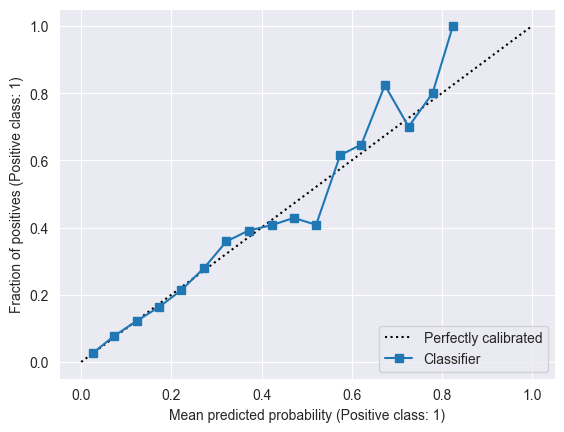

In [27]:
fig = generate_four_curves("xgb_all_features_auc_tuning_2", y_test, model.predict_proba(X_test)[:,1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
print(f"f1 score: {f1}")

Finalement, après toutes ces expériences qu'on a faites, l'ensemble de paramètre suivant donne le meilleur résultat.

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nassim-walha/ds-milestone2/e63bb4e2314b4d98a9131d1a66903b75



Accuracy on training data:  0.91
Accuracy on testing data:  91.04
f1 score: 0.4973061828280788


COMET INFO: ---------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     url                   : https://www.comet.com/nassim-walha/ds-milestone2/e63bb4e2314b4d98a9131d1a66903b75
COMET INFO:   Metrics:
COMET INFO:     accuracy : 0.9103630736463776
COMET INFO:     auc      : 0.7520307518165245
COMET INFO:     f1_score : 0.4973061828280788
COMET INFO:   Parameters:
COMET INFO:     begin_iteration : 0
COMET INFO:     end_iteration   : 99
COMET INFO:     gamma           : 1.8
COMET INFO:     max_delta_step  : 6
COMET INFO:     max_depth       : 5
COMET INFO:     objective       : binary:logistic
COMET INFO:     rank            : 0
COMET INFO:     world_size      : 1
COMET INFO:   Uploads:
COMET INFO:     conda-environment-definition : 1
COMET INFO:     conda-info                   : 1
COMET INFO:     conda-specification          : 1
COMET INFO:     environment detail

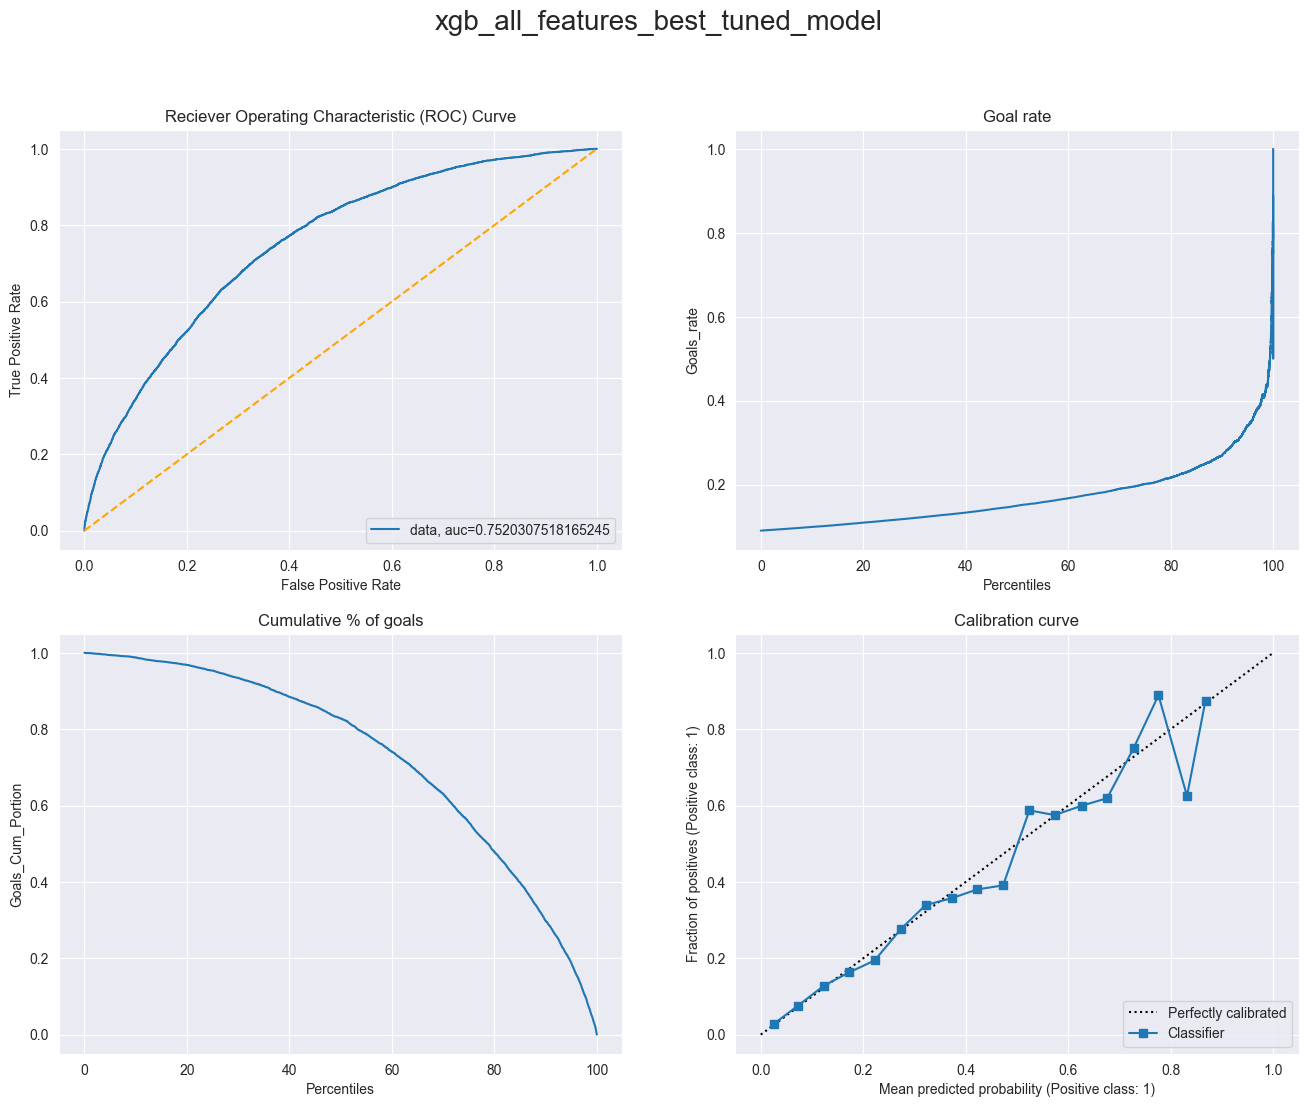

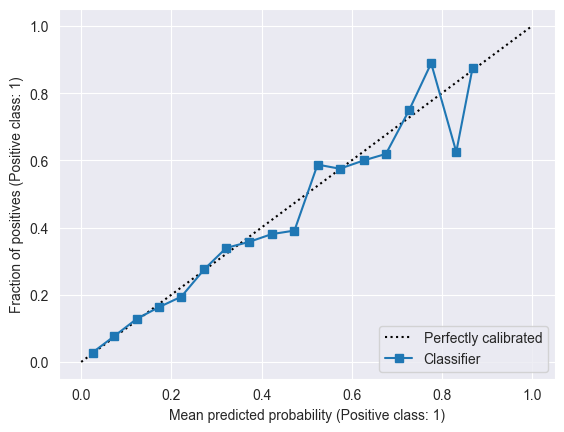

In [30]:
#model = grid_search.best_estimator_
#exp = Experiment(api_key=os.environ.get("COMET_API_KEY"), workspace="nassim-walha", project_name="ds-milestone2")
#exp.add_tag("XGBOOST Tuned ALL Features")
model = xgb.XGBClassifier(max_depth=5, max_delta_step=6, gamma=1.8)
                          #eta=0.12857142857142856,
                          #tree_method='gpu_hist')
model.fit(X_train, y_train)

print('Accuracy on training data: ', round(model.score(X_train,y_train),2))
result = model.score(X_test,y_test)
print('Accuracy on testing data: ', round(result*100,2))
fig = generate_four_curves("xgb_all_features_best_tuned_model", y_test, model.predict_proba(X_test)[:, 1], 20)
f1 = metrics.f1_score(y_test, model.predict(X_test), average='macro')
print(f"f1 score: {f1}")
auc = metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
#exp.log_metric("accuracy", result)
#exp.log_metric("f1_score", f1)
#exp.log_metric("auc", auc)
#model.save_model("models/xgb_tuned_all_features.json")
#exp.log_model("XGB TUNED ALL", "models/xgb_tuned_all_features.json")
#exp.end()

Ce modèle est meilleur en terme de AUC (0.75 vs 0.74) et en terme de calibration, par rapport au modèle avec toutes les caractéristiques mais sans Optimization d'Hypermaramètres. Mais l'amélioration est très légère et on peut mieux faire. Il semble que l'optimization d'Hyperparamètres n'a pas donné grande chose.

## FEATURE SELECTION

In [99]:
df.corr().iloc[:,0:9].style.background_gradient(cmap='Blues')

C:\Users\GM\AppData\Local\Temp\ipykernel_36136\2641464027.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr().iloc[:,0:9].style.background_gradient(cmap='Blues')


,Period_Time_Seconds,Period,X_Coordinate,Y_Coordinate,Distance_Net,Angle,Last_Coordinate_X,Last_Coordinate_Y,Time_Between_Events
Period_Time_Seconds,1.000000,-0.046654,-0.004644,-0.000923,0.007301,-0.001094,-0.003250,-0.003241,0.021502
Period,-0.046654,1.000000,0.000981,0.001343,-0.005571,-0.001425,0.004282,0.000488,0.051645
X_Coordinate,-0.004644,0.000981,1.000000,-0.008387,-0.005625,-0.030282,0.378855,-0.003693,-0.002531
Y_Coordinate,-0.000923,0.001343,-0.008387,1.000000,0.003401,0.830901,-0.004530,0.045930,-0.009678
Distance_Net,0.007301,-0.005571,-0.005625,0.003401,1.000000,0.009876,-0.005964,0.002199,0.037302
Angle,-0.001094,-0.001425,-0.030282,0.830901,0.009876,1.000000,-0.010404,0.046840,-0.004900
Last_Coordinate_X,-0.003250,0.004282,0.378855,-0.004530,-0.005964,-0.010404,1.000000,-0.011573,-0.000818
Last_Coordinate_Y,-0.003241,0.000488,-0.003693,0.045930,0.002199,0.046840,-0.011573,1.000000,0.003816
Time_Between_Events,0.021502,0.051645,-0.002531,-0.009678,0.037302,-0.004900,-0.000818,0.003816,1.000000
Distance_Last_Event,-0.022785,0.005767,-0.001263,-0.005558,0.000698,-0.003244,0.003200,0.005486,0.175675


In [105]:
df.corr().iloc[:,9:17].style.background_gradient(cmap='Blues')

C:\Users\GM\AppData\Local\Temp\ipykernel_36136\380200543.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr().iloc[:,9:17].style.background_gradient(cmap='Blues')


,Distance_Last_Event,Rebond,Delta_Angle,Speed,Powerplay_Since,Friendly_Non_Goalies,Opponent_Non_Goalies,is_goal
Period_Time_Seconds,-0.022785,-0.001199,-0.000933,-0.017468,0.064191,-0.050483,-0.070739,0.023842
Period,0.005767,0.014270,0.000301,-0.036807,-0.018078,0.020692,0.025144,0.032967
X_Coordinate,-0.001263,0.003003,-0.021178,0.001549,-0.001922,0.001048,0.001033,-0.001286
Y_Coordinate,-0.005558,0.005687,0.780913,0.008777,0.010459,-0.004917,-0.013395,0.006184
Distance_Net,0.000698,-0.087877,0.007439,-0.028340,-0.002886,-0.069562,0.042355,-0.111123
Angle,-0.003244,0.001290,0.928821,0.005741,0.008073,-0.003849,-0.012384,0.004999
Last_Coordinate_X,0.003200,0.000607,-0.001423,0.002406,-0.000853,0.000778,-0.000240,-0.001402
Last_Coordinate_Y,0.005486,-0.004896,-0.054995,0.000601,0.006019,-0.003146,-0.006689,0.003442
Time_Between_Events,0.175675,-0.067141,-0.006439,-0.417052,0.082103,0.005352,-0.054388,-0.045707
Distance_Last_Event,1.000000,-0.101173,-0.006293,0.308100,-0.114093,-0.053278,0.184224,-0.024297


A partir de la matrice de corrélation, on remarque que les caractérisiques suivantes sont redondantes: <br>
- Time_Between_Events: Redondant avec Speed.
- Distance_Last_Event: Redondant avec Speed.
- X_Coordinate: Redondant avec Last_Coordinate_X.
- Y_Coordinate: Redondant avec Angle.
- Delta_Angle: Redondant avec Y_Coodinate et Angle.
- Power_Play_Since: Redondant avec Friendly_Non_Goalies et Opponent_Non_Goalies

Maintenant on va essayer 3 méthodes différentes pour sélectionner les 8 meilleures caractéristiques. Après on pourra aggréger les résultat dans un ensemble de caractéristiques qu'on espère être le meilleur.

Feature Selection KBest using mutual information

In [106]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
my_selector = SelectKBest(mutual_info_classif, k=8)
my_selector.fit(X_train,y_train)
features_out = my_selector.get_feature_names_out()
features_out_indices = [int(s[1:]) for s  in features_out]

In [107]:
transformed_features[features_out_indices]

array(['standard__Y_Coordinate', 'standard__Distance_Net',
       'standard__Angle', 'standard__Powerplay_Since',
       'one-hot__Shoot_Type_Wrist Shot', 'remainder__Period',
       'remainder__Friendly_Non_Goalies',
       'remainder__Opponent_Non_Goalies'], dtype=object)

Selected features: ['standard__Y_Coordinate', 'standard__Distance_Net',
       'standard__Angle', 'standard__Powerplay_Since',
       'one-hot__Shoot_Type_Wrist Shot', 'remainder__Period',
       'remainder__Friendly_Non_Goalies',
       'remainder__Opponent_Non_Goalies']

In [108]:
my_selector.scores_

array([0.00133783, 0.01302507, 0.01693549, 0.01992288, 0.01391235,
       0.00225974, 0.00314735, 0.00645916, 0.00340685, 0.00841189,
       0.00690258, 0.01303995, 0.00058624, 0.00041031, 0.00211402,
       0.00058575, 0.00327032, 0.        , 0.0140558 , 0.00100356,
       0.0032308 , 0.00037995, 0.00096207, 0.0025529 , 0.00054482,
       0.        , 0.0021339 , 0.        , 0.01343866, 0.00235466,
       0.04781545, 0.04095941])

Feature Selection Lasso

In [112]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel
my_log_reg = LogisticRegression(penalty='l1', solver="liblinear")
selector = SelectFromModel(my_log_reg, max_features=8).fit(X_train,y_train)
features_out = selector.get_feature_names_out()
features_out_indices = [int(s[1:]) for s  in features_out]
transformed_features[features_out_indices]

array(['standard__Distance_Net', 'one-hot__Shoot_Type_Backhand',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'one-hot__Last_Event_Type_Faceoff', 'one-hot__Last_Event_Type_Hit'],
      dtype=object)

Selected_features: ['standard__Distance_Net', 'one-hot__Shoot_Type_Backhand',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'one-hot__Last_Event_Type_Faceoff', 'one-hot__Last_Event_Type_Hit']


Sequential Feature Selector in Forward Direction

In [114]:
from sklearn.feature_selection import  SequentialFeatureSelector
feature_selector = SequentialFeatureSelector(xgb.XGBClassifier(tree_method= 'gpu_hist'), n_features_to_select=8, direction="forward", scoring="f1")

In [115]:
%%time
feature_selector.fit(X_train,y_train)

CPU times: total: 1h 8min 11s
Wall time: 7min 42s


SequentialFeatureSelector(estimator=XGBClassifier(base_score=None, booster=None,
                                                  callbacks=None,
                                                  colsample_bylevel=None,
                                                  colsample_bynode=None,
                                                  colsample_bytree=None,
                                                  early_stopping_rounds=None,
                                                  enable_categorical=False,
                                                  eval_metric=None,
                                                  feature_types=None,
                                                  gamma=None, gpu_id=None,
                                                  grow_policy=None,
                                                  importance_type=None,
                                                  interaction_constraints=None,
                                                  learning_rate=None,
                                                  max_bin=None,
                                                  max_cat_threshold=None,
                                                  max_cat_to_onehot=None,
                                                  max_delta_step=None,
                                                  max_depth=None,
                                                  max_leaves=None,
                                                  min_child_weight=None,
                                                  missing=nan,
                                                  monotone_constraints=None,
                                                  n_estimators=100, n_jobs=None,
                                                  num_parallel_tree=None,
                                                  predictor=None,
                                                  random_state=None, ...),
                          n_features_to_select=8, scoring='f1')

In [116]:
features_out = feature_selector.get_feature_names_out()
features_out_indices = [int(s[1:]) for s  in features_out]
transformed_features[features_out_indices]

array(['standard__Period_Time_Seconds', 'standard__X_Coordinate',
       'standard__Distance_Net', 'standard__Distance_Last_Event',
       'standard__Speed', 'standard__Powerplay_Since',
       'one-hot__Shoot_Type_Tip-In', 'remainder__Period'], dtype=object)

Selected Features: ['standard__Period_Time_Seconds', 'standard__X_Coordinate',
       'standard__Distance_Net', 'standard__Distance_Last_Event',
       'standard__Speed', 'standard__Powerplay_Since',
       'one-hot__Shoot_Type_Tip-In', 'remainder__Period']

En examinant les différents résultats, on finit par prendre l'ensemble de caractéristiques suivant

In [31]:
selected_features = ["Period", "Period_Time_Seconds", "Distance_Net", "Angle", "X_Coordinate", "Speed",
                     "Friendly_Non_Goalies", "Opponent_Non_Goalies", "Shoot_Type"]

In [32]:
df_selected_features = df[selected_features]
df_selected_features["is_goal"] =df['is_goal']
X_train_selected, X_test_selected, y_train_selected, y_test_selected = train_test_split(df_selected_features.iloc[:,:-1], df_selected_features.iloc[:,-1], test_size = 0.20, random_state=42)
selected_features_to_standardize = ["Period", "Period_Time_Seconds", "Distance_Net", "Angle", "X_Coordinate", "Speed"]
selected_features_one_hot = ['Shoot_Type']

my_transformer_selected = ColumnTransformer([('standard', StandardScaler(), selected_features_to_standardize),
                                    ('one-hot', OneHotEncoder(), selected_features_one_hot)],
                                   remainder='passthrough')
X_train_selected = my_transformer_selected.fit_transform(X_train_selected)
X_test_selected = my_transformer_selected.transform(X_test_selected)
y_test_selected.reset_index(inplace= True, drop=True)
y_train_selected.reset_index(inplace= True, drop=True)
transformed_features_selected = my_transformer_selected.get_feature_names_out()
transformed_features_selected

/var/folders/yp/s64kzpxd3k95zytpqbx3y1tw0000gn/T/ipykernel_1336/654879246.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_selected_features["is_goal"] =df['is_goal']


array(['standard__Period', 'standard__Period_Time_Seconds',
       'standard__Distance_Net', 'standard__Angle',
       'standard__X_Coordinate', 'standard__Speed',
       'one-hot__Shoot_Type_Backhand', 'one-hot__Shoot_Type_Deflected',
       'one-hot__Shoot_Type_Slap Shot', 'one-hot__Shoot_Type_Snap Shot',
       'one-hot__Shoot_Type_Tip-In', 'one-hot__Shoot_Type_Wrap-around',
       'one-hot__Shoot_Type_Wrist Shot',
       'remainder__Friendly_Non_Goalies',
       'remainder__Opponent_Non_Goalies'], dtype=object)

Maintenant on refait de l'hyperparameter tuning avec les caractéristiques sélectionnées.

In [45]:
from sklearn.model_selection import RandomizedSearchCV


tuned_parameters = {
  'gamma': np.linspace(0, 3, num=70),
  'max_depth': np.linspace(0, 12, num=13, dtype=int),
    'max_delta_step': np.linspace(0,10, num=11),

  }



grid_search = RandomizedSearchCV(
    xgb.XGBClassifier(tree_method="gpu_hist"), tuned_parameters, n_iter=250, scoring='roc_auc', cv=5,
)
grid_search.fit(X_train_selected, y_train_selected);
print('Finished!')

Finished!


In [46]:
print("Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:")
print()
print(grid_search.best_params_)
print(grid_search.best_score_)

Meilleur ensemble de paramètres trouvé sur l'ensemble de développement:

{'max_depth': 5, 'max_delta_step': 9.0, 'gamma': 2.217391304347826}
0.7476273694814021


In [33]:
#model = grid_search.best_estimator_
exp = Experiment(api_key=os.environ.get("COMET_API_KEY"), workspace="nassim-walha", project_name="ds-milestone2")
exp.add_tag("XGBOOST Tuned SELECTED Features")
model = xgb.XGBClassifier(max_depth= 5, max_delta_step = 9, gamma= 2.217391304347826)
                          #tree_method = 'gpu_hist')
model.fit(X_train_selected, y_train_selected)
print('Accuracy on training data: ', round(model.score(X_train_selected,y_train_selected),2))
result = model.score(X_test_selected,y_test_selected)
print('Accuracy on testing data: ', round(result*100,2))

COMET WARNING: As you are running in a Jupyter environment, you will need to call `experiment.end()` when finished to ensure all metrics and code are logged before exiting.
COMET INFO: Experiment is live on comet.com https://www.comet.com/nassim-walha/ds-milestone2/a90f28dd8b0e4cf289de0eab6390d168



Accuracy on training data:  0.91
Accuracy on testing data:  90.95


f1 score: 0.4886525984307951


COMET INFO: ---------------------------
COMET INFO: Comet.ml Experiment Summary
COMET INFO: ---------------------------
COMET INFO:   Data:
COMET INFO:     display_summary_level : 1
COMET INFO:     url                   : https://www.comet.com/nassim-walha/ds-milestone2/a90f28dd8b0e4cf289de0eab6390d168
COMET INFO:   Metrics:
COMET INFO:     accuracy : 0.9095144597157976
COMET INFO:     auc      : 0.7425341794952411
COMET INFO:     f1_score : 0.4886525984307951
COMET INFO:   Parameters:
COMET INFO:     begin_iteration : 0
COMET INFO:     end_iteration   : 99
COMET INFO:     gamma           : 2.217391304347826
COMET INFO:     max_delta_step  : 9
COMET INFO:     max_depth       : 5
COMET INFO:     objective       : binary:logistic
COMET INFO:     rank            : 0
COMET INFO:     world_size      : 1
COMET INFO:   Uploads:
COMET INFO:     conda-environment-definition : 1
COMET INFO:     conda-info                   : 1
COMET INFO:     conda-specification          : 1
COMET INFO:     envi

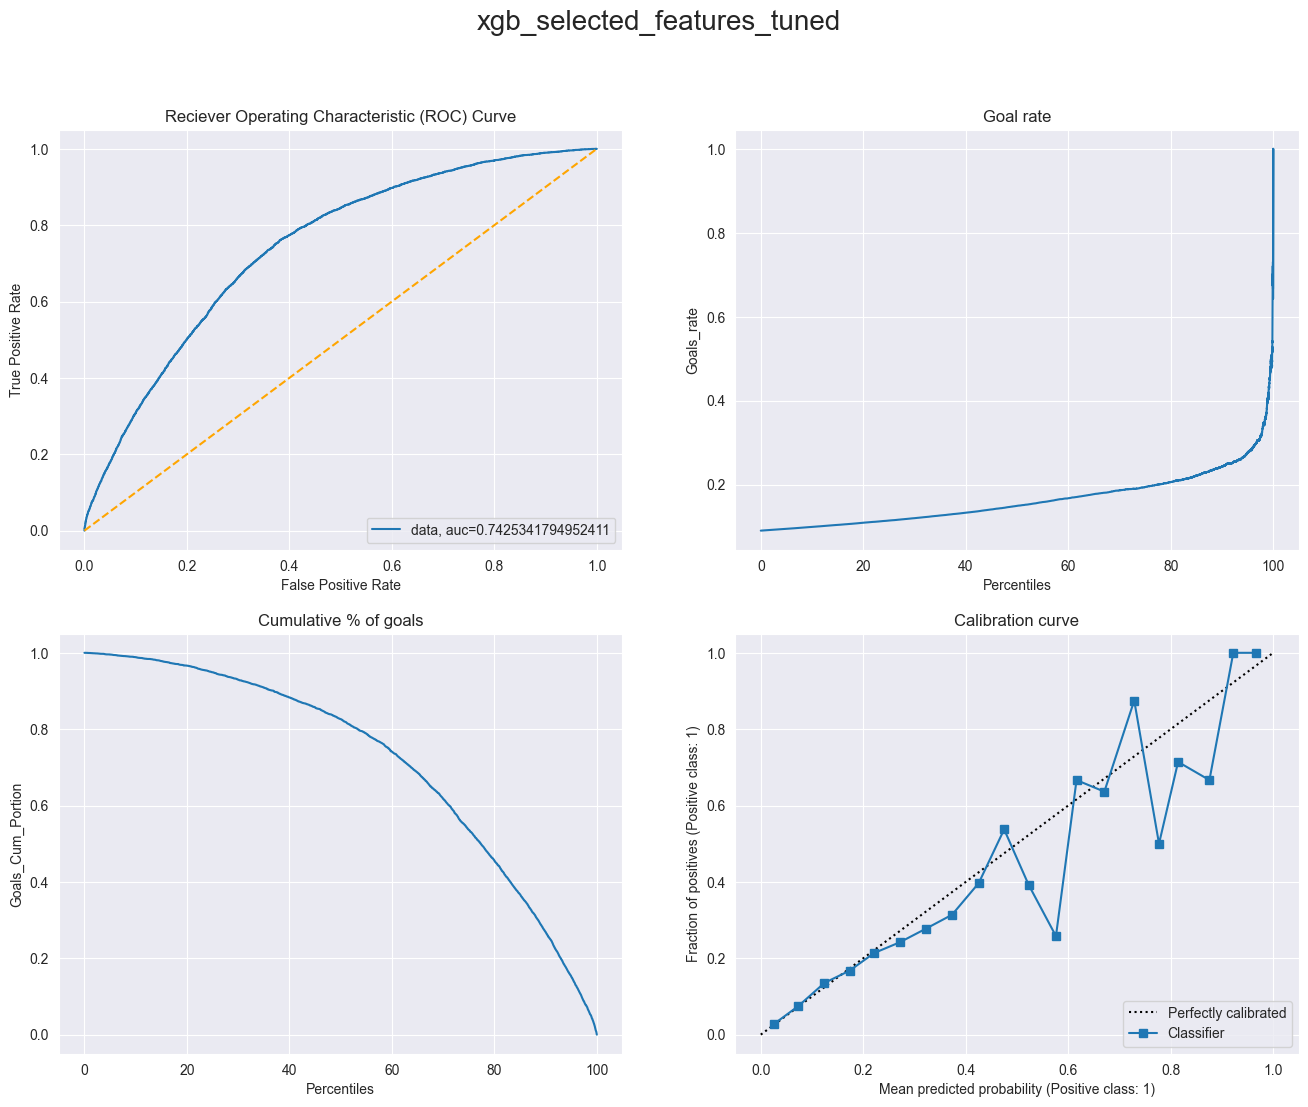

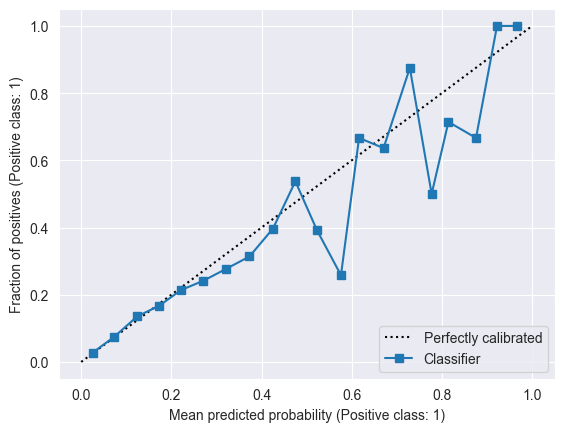

In [34]:
fig = generate_four_curves("xgb_selected_features_tuned", y_test_selected, model.predict_proba(X_test_selected)[:,1], 20)
f1 = metrics.f1_score(y_test_selected, model.predict(X_test_selected), average='macro')
print(f"f1 score: {f1}")
auc = metrics.roc_auc_score(y_test_selected, model.predict_proba(X_test_selected)[:,1])
exp.log_metric("accuracy", result)
exp.log_metric("f1_score", f1)
exp.log_metric("auc", auc)
model.save_model("models/xgb_tuned_selected_features.json")
exp.log_model("XGB TUNED SELECTED", "models/xgb_tuned_selected_features.json")
exp.end()

Conclusion: Par rapport à l'entrainement par angle et distance seulement, on obtient un AUC meilleur (0.74 vs 0.70) et une meilleure calibration. Par rapport à l'entrainement par toutes les caractéristiques (32 caractéristiques), on obtient une performance légèrement inférieure, mais très comparable(AUC: 0.74 vs 0.75), et la calibration est moins bonne. Ceci est du au fait que XGBOOST n'est pas affecté par les caractéristiques redondantes, ce qui fait que plus on a de caractéristiques, plus le résultat a tendance à s'améliorer. Cependant, l'amélioration ne vaut pas le coût d'ajouter 17 caractéristiques (l'ensemble de caracéristiques sélectionnées compte 15 caractéristiques en inculuant les one-hot-encodings). En plus dans la prochaine étape, on va utiliser d'autres modèles qui sont affectés par les caractéristiques redondantes, donc on décide de ne garder que les caractéristiques sélectionnées.